# Poisson Part Two: Electric Boogaloo

The last Poisson Model worked, but not that well. Let's work to make a better one

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
url = "https://raw.githubusercontent.com/hankike/Premier_Prediction/refs/heads/main/data/cleaned_premier.csv"

df = pd.read_csv(url)

print(df.shape)
print(df.columns.tolist())
df.head()

(2660, 24)
['Div', 'Date', 'Time', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'Referee', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR']


,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
0,E0,15/08/2025,20:00,Liverpool,Bournemouth,4,2,H,1,0,...,10,3,7,10,6,7,1,2,0,0
1,E0,16/08/2025,12:30,Aston Villa,Newcastle,0,0,D,0,0,...,3,3,13,11,3,6,1,1,1,0
2,E0,16/08/2025,15:00,Brighton,Fulham,1,1,D,0,0,...,4,2,16,15,4,3,3,3,0,0
3,E0,16/08/2025,15:00,Sunderland,West Ham,3,0,H,0,0,...,5,4,8,10,5,7,0,1,0,0
4,E0,16/08/2025,15:00,Tottenham,Burnley,3,0,H,1,0,...,6,4,14,8,6,5,0,0,0,0


Next we do some data checks to test our data. First we will look at column data types and then count any missing values

In [4]:
# Inspect column data types
df.info()

# Count missing values in each column
df.isnull().sum()


<class 'pandas.DataFrame'>
RangeIndex: 2660 entries, 0 to 2659
Data columns (total 24 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Div       2660 non-null   str  
 1   Date      2660 non-null   str  
 2   Time      2660 non-null   str  
 3   HomeTeam  2660 non-null   str  
 4   AwayTeam  2660 non-null   str  
 5   FTHG      2660 non-null   int64
 6   FTAG      2660 non-null   int64
 7   FTR       2660 non-null   str  
 8   HTHG      2660 non-null   int64
 9   HTAG      2660 non-null   int64
 10  HTR       2660 non-null   str  
 11  Referee   2660 non-null   str  
 12  HS        2660 non-null   int64
 13  AS        2660 non-null   int64
 14  HST       2660 non-null   int64
 15  AST       2660 non-null   int64
 16  HF        2660 non-null   int64
 17  AF        2660 non-null   int64
 18  HC        2660 non-null   int64
 19  AC        2660 non-null   int64
 20  HY        2660 non-null   int64
 21  AY        2660 non-null   int64
 22  HR        2

Div         0
Date        0
Time        0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
HTHG        0
HTAG        0
HTR         0
Referee     0
HS          0
AS          0
HST         0
AST         0
HF          0
AF          0
HC          0
AC          0
HY          0
AY          0
HR          0
AR          0
dtype: int64

Next, we need a time statistic so we know how to train our data. We are looking to sort values by the date that they happened

In [5]:
# Convert Date to datetime
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Sort matches chronologically
df = df.sort_values(['Date', 'Time']).reset_index(drop=True)

# Inspect the result
print("Earliest match:", df['Date'].min())
print("Latest match:", df['Date'].max())

df[['Date', 'Time', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG']].head()


Earliest match: 2019-08-09 00:00:00
Latest match: 2026-05-24 00:00:00


,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG
0,2019-08-09,20:00,Liverpool,Norwich,4,1
1,2019-08-10,12:30,West Ham,Man City,0,5
2,2019-08-10,15:00,Bournemouth,Sheffield United,1,1
3,2019-08-10,15:00,Burnley,Southampton,3,0
4,2019-08-10,15:00,Crystal Palace,Everton,0,0


# Filter based on seasons

We have seven seasons worth of data in this dataset, so let us filter it in order to assign each a season.

In [6]:
# Identify the starting year of each season
season_start = np.where(
    df['Date'].dt.month >= 8,
    df['Date'].dt.year,
    df['Date'].dt.year - 1
)

season_start = pd.Series(season_start, index=df.index)

# Create season labels
df['Season'] = (
    season_start.astype(str) + '/' +
    (season_start + 1).astype(str).str[-2:]
)

# Check season counts and date ranges
print(df.groupby('Season').size())

df.groupby('Season')['Date'].agg(['min', 'max'])

Season
2019/20    380
2020/21    380
2021/22    380
2022/23    380
2023/24    380
2024/25    380
2025/26    380
dtype: int64


,min,max
Season,,
2019/20,2019-08-09,2020-07-26
2020/21,2020-09-12,2021-05-23
2021/22,2021-08-13,2022-05-22
2022/23,2022-08-05,2023-05-28
2023/24,2023-08-11,2024-05-19
2024/25,2024-08-16,2025-05-25
2025/26,2025-08-15,2026-05-24


In [7]:
league_home_goals = df['FTHG'].mean()
league_away_goals = df['FTAG'].mean()

print(f"Average home goals: {league_home_goals:.3f}")
print(f"Average away goals: {league_away_goals:.3f}")
print(f"Average total goals: {df[['FTHG', 'FTAG']].to_numpy().mean():.3f}")


Average home goals: 1.551
Average away goals: 1.314
Average total goals: 1.432


In [8]:
# Home team records
home_df = df[['Date', 'Time', 'Season', 'HomeTeam',
              'AwayTeam', 'FTHG', 'FTAG']].copy()

home_df.columns = [
    'Date', 'Time', 'Season', 'Team',
    'Opponent', 'Goals_Scored', 'Goals_Conceded'
]

home_df['Venue'] = 'Home'


# Away team records
away_df = df[['Date', 'Time', 'Season', 'AwayTeam',
              'HomeTeam', 'FTAG', 'FTHG']].copy()

away_df.columns = [
    'Date', 'Time', 'Season', 'Team',
    'Opponent', 'Goals_Scored', 'Goals_Conceded'
]

away_df['Venue'] = 'Away'


# Combine both datasets
team_df = pd.concat([home_df, away_df], ignore_index=True)

# Sort chronologically
team_df = team_df.sort_values(
    ['Date', 'Time', 'Team']
).reset_index(drop=True)

# Inspect
print(team_df.shape)
team_df.head(10)


(5320, 8)


,Date,Time,Season,Team,Opponent,Goals_Scored,Goals_Conceded,Venue
0,2019-08-09,20:00,2019/20,Liverpool,Norwich,4,1,Home
1,2019-08-09,20:00,2019/20,Norwich,Liverpool,1,4,Away
2,2019-08-10,12:30,2019/20,Man City,West Ham,5,0,Away
3,2019-08-10,12:30,2019/20,West Ham,Man City,0,5,Home
4,2019-08-10,15:00,2019/20,Bournemouth,Sheffield United,1,1,Home
5,2019-08-10,15:00,2019/20,Brighton,Watford,3,0,Away
6,2019-08-10,15:00,2019/20,Burnley,Southampton,3,0,Home
7,2019-08-10,15:00,2019/20,Crystal Palace,Everton,0,0,Home
8,2019-08-10,15:00,2019/20,Everton,Crystal Palace,0,0,Away
9,2019-08-10,15:00,2019/20,Sheffield United,Bournemouth,1,1,Away


In [9]:
# Calculate 5-match rolling averages using previous matches only

team_df['Avg_Goals_Scored_5'] = (
    team_df.groupby('Team')['Goals_Scored']
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())
)

team_df['Avg_Goals_Conceded_5'] = (
    team_df.groupby('Team')['Goals_Conceded']
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())
)

# Inspect results
team_df[['Date', 'Team', 'Goals_Scored',
         'Avg_Goals_Scored_5', 'Avg_Goals_Conceded_5']].head(15)


,Date,Team,Goals_Scored,Avg_Goals_Scored_5,Avg_Goals_Conceded_5
0,2019-08-09,Liverpool,4,NaN,NaN
1,2019-08-09,Norwich,1,NaN,NaN
2,2019-08-10,Man City,5,NaN,NaN
3,2019-08-10,West Ham,0,NaN,NaN
4,2019-08-10,Bournemouth,1,NaN,NaN
5,2019-08-10,Brighton,3,NaN,NaN
6,2019-08-10,Burnley,3,NaN,NaN
7,2019-08-10,Crystal Palace,0,NaN,NaN
8,2019-08-10,Everton,0,NaN,NaN
9,2019-08-10,Sheffield United,1,NaN,NaN


In [10]:
team_df[team_df['Team'] == 'Liverpool'][
    ['Date', 'Opponent', 'Goals_Scored',
     'Avg_Goals_Scored_5', 'Avg_Goals_Conceded_5']
].head(10)

,Date,Opponent,Goals_Scored,Avg_Goals_Scored_5,Avg_Goals_Conceded_5
0,2019-08-09,Norwich,4,NaN,NaN
26,2019-08-17,Southampton,2,4.0,1.00
53,2019-08-24,Arsenal,3,3.0,1.00
75,2019-08-31,Burnley,3,3.0,1.00
80,2019-09-14,Newcastle,3,3.0,0.75
119,2019-09-22,Chelsea,2,3.0,0.80
120,2019-09-28,Sheffield United,1,2.6,0.80
146,2019-10-05,Leicester,2,2.4,0.60
176,2019-10-20,Man United,1,2.2,0.60
196,2019-10-27,Tottenham,2,1.8,0.80


In [11]:
print("Missing attacking averages:")
print(team_df['Avg_Goals_Scored_5'].isna().sum())

print("\nMissing defensive averages:")
print(team_df['Avg_Goals_Conceded_5'].isna().sum())

print("\nTeams with missing attacking averages:")
print(
    team_df.loc[
        team_df['Avg_Goals_Scored_5'].isna(), 'Team'
    ].unique()
)

Missing attacking averages:
28

Missing defensive averages:
28

Teams with missing attacking averages:
<StringArray>
[       'Liverpool',          'Norwich',         'Man City',
         'West Ham',      'Bournemouth',         'Brighton',
          'Burnley',   'Crystal Palace',          'Everton',
 'Sheffield United',      'Southampton',          'Watford',
      'Aston Villa',        'Tottenham',          'Arsenal',
        'Leicester',        'Newcastle',           'Wolves',
          'Chelsea',       'Man United',           'Fulham',
            'Leeds',        'West Brom',        'Brentford',
    'Nott'm Forest',            'Luton',          'Ipswich',
       'Sunderland']
Length: 28, dtype: str


In [12]:
df['Total_Goals'] = df['FTHG'] + df['FTAG']

# Group matches by kickoff date and time
kickoff_groups = df.groupby(['Date', 'Time'], sort=True)

# Calculate goals scored at each kickoff
kickoff_totals = kickoff_groups[['FTHG', 'FTAG']].sum()

# Calculate cumulative totals BEFORE each kickoff
previous_totals = kickoff_totals.cumsum().shift(1).fillna(0)

# Count matches played before each kickoff
previous_matches = kickoff_groups.size().cumsum().shift(1).fillna(0)

# Calculate historical league averages
league_averages = previous_totals.div(previous_matches, axis=0)

# Map averages back to every match
df = df.join(
    league_averages.rename(columns={
        'FTHG': 'League_Avg_Home_Goals',
        'FTAG': 'League_Avg_Away_Goals'
    }),
    on=['Date', 'Time']
)

df[['Date', 'Time', 'FTHG', 'FTAG',
    'League_Avg_Home_Goals', 'League_Avg_Away_Goals']].head(10)

,Date,Time,FTHG,FTAG,League_Avg_Home_Goals,League_Avg_Away_Goals
0,2019-08-09,20:00,4,1,NaN,NaN
1,2019-08-10,12:30,0,5,4.000000,1.000000
2,2019-08-10,15:00,1,1,2.000000,3.000000
3,2019-08-10,15:00,3,0,2.000000,3.000000
4,2019-08-10,15:00,0,0,2.000000,3.000000
5,2019-08-10,15:00,0,3,2.000000,3.000000
6,2019-08-10,17:30,3,1,1.333333,1.666667
7,2019-08-11,14:00,0,0,1.571429,1.571429
8,2019-08-11,14:00,0,1,1.571429,1.571429
9,2019-08-11,16:30,4,0,1.222222,1.333333


In [13]:
# Create a lookup table containing one row per kickoff
league_lookup = (
    df[['Date', 'Time', 'League_Avg_Home_Goals',
        'League_Avg_Away_Goals']]
    .drop_duplicates()
)

team_df = team_df.merge(
    league_lookup,
    on=['Date', 'Time'],
    how='left'
)

team_df.head()

,Date,Time,Season,Team,Opponent,Goals_Scored,Goals_Conceded,Venue,Avg_Goals_Scored_5,Avg_Goals_Conceded_5,League_Avg_Home_Goals,League_Avg_Away_Goals
0,2019-08-09,20:00,2019/20,Liverpool,Norwich,4,1,Home,NaN,NaN,NaN,NaN
1,2019-08-09,20:00,2019/20,Norwich,Liverpool,1,4,Away,NaN,NaN,NaN,NaN
2,2019-08-10,12:30,2019/20,Man City,West Ham,5,0,Away,NaN,NaN,4.0,1.0
3,2019-08-10,12:30,2019/20,West Ham,Man City,0,5,Home,NaN,NaN,4.0,1.0
4,2019-08-10,15:00,2019/20,Bournemouth,Sheffield United,1,1,Home,NaN,NaN,2.0,3.0


In [14]:
print("Team dataframe shape:", team_df.shape)

print("\nMissing league averages:")
print(
    team_df[
        ['League_Avg_Home_Goals', 'League_Avg_Away_Goals']
    ].isna().sum()
)

print("\nDuplicate team-match records:")
print(
    team_df.duplicated(
        subset=['Date', 'Time', 'Team', 'Opponent']
    ).sum()
)

Team dataframe shape: (5320, 12)

Missing league averages:
League_Avg_Home_Goals    2
League_Avg_Away_Goals    2
dtype: int64

Duplicate team-match records:
0


In [15]:
print(
    team_df[
        ['Avg_Goals_Scored_5',
         'Avg_Goals_Conceded_5']
    ].isna().sum()
)

Avg_Goals_Scored_5      28
Avg_Goals_Conceded_5    28
dtype: int64


In [16]:
# Fill missing attacking averages using venue-specific league averages
team_df['Avg_Goals_Scored_5'] = np.where(
    team_df['Venue'] == 'Home',
    team_df['Avg_Goals_Scored_5'].fillna(
        team_df['League_Avg_Home_Goals']
    ),
    team_df['Avg_Goals_Scored_5'].fillna(
        team_df['League_Avg_Away_Goals']
    )
)

# Fill missing defensive averages using the opposing venue baseline
team_df['Avg_Goals_Conceded_5'] = np.where(
    team_df['Venue'] == 'Home',
    team_df['Avg_Goals_Conceded_5'].fillna(
        team_df['League_Avg_Away_Goals']
    ),
    team_df['Avg_Goals_Conceded_5'].fillna(
        team_df['League_Avg_Home_Goals']
    )
)

In [17]:
print(
    team_df[
        ['Avg_Goals_Scored_5',
         'Avg_Goals_Conceded_5']
    ].isna().sum()
)

Avg_Goals_Scored_5      2
Avg_Goals_Conceded_5    2
dtype: int64


In [18]:
# Initial baseline for the first match in our dataset
team_df['Avg_Goals_Scored_5'] = np.where(
    team_df['Avg_Goals_Scored_5'].isna() & (team_df['Venue'] == 'Home'),
    1.45,
    team_df['Avg_Goals_Scored_5']
)

team_df['Avg_Goals_Scored_5'] = np.where(
    team_df['Avg_Goals_Scored_5'].isna() & (team_df['Venue'] == 'Away'),
    1.15,
    team_df['Avg_Goals_Scored_5']
)

team_df['Avg_Goals_Conceded_5'] = np.where(
    team_df['Avg_Goals_Conceded_5'].isna() & (team_df['Venue'] == 'Home'),
    1.15,
    team_df['Avg_Goals_Conceded_5']
)

team_df['Avg_Goals_Conceded_5'] = np.where(
    team_df['Avg_Goals_Conceded_5'].isna() & (team_df['Venue'] == 'Away'),
    1.45,
    team_df['Avg_Goals_Conceded_5']
)

In [19]:
print(
    team_df[
        ['Avg_Goals_Scored_5',
         'Avg_Goals_Conceded_5']
    ].isna().sum()
)

Avg_Goals_Scored_5      0
Avg_Goals_Conceded_5    0
dtype: int64


In [20]:
team_df[
    ['Date', 'Team', 'Opponent', 'Venue',
     'Avg_Goals_Scored_5', 'Avg_Goals_Conceded_5']
].head(10)

,Date,Team,Opponent,Venue,Avg_Goals_Scored_5,Avg_Goals_Conceded_5
0,2019-08-09,Liverpool,Norwich,Home,1.45,1.15
1,2019-08-09,Norwich,Liverpool,Away,1.15,1.45
2,2019-08-10,Man City,West Ham,Away,1.00,4.00
3,2019-08-10,West Ham,Man City,Home,4.00,1.00
4,2019-08-10,Bournemouth,Sheffield United,Home,2.00,3.00
5,2019-08-10,Brighton,Watford,Away,3.00,2.00
6,2019-08-10,Burnley,Southampton,Home,2.00,3.00
7,2019-08-10,Crystal Palace,Everton,Home,2.00,3.00
8,2019-08-10,Everton,Crystal Palace,Away,3.00,2.00
9,2019-08-10,Sheffield United,Bournemouth,Away,3.00,2.00


# Update the dataset

Now we want to make every game equal to one row. This way we are not using games happening as a previous game

In [21]:
# Extract home-team features
home_features = team_df[
    team_df['Venue'] == 'Home'
][[
    'Date', 'Time', 'Team', 'Opponent',
    'Avg_Goals_Scored_5', 'Avg_Goals_Conceded_5'
]].rename(columns={
    'Team': 'HomeTeam',
    'Opponent': 'AwayTeam',
    'Avg_Goals_Scored_5': 'Home_Avg_Goals_Scored_5',
    'Avg_Goals_Conceded_5': 'Home_Avg_Goals_Conceded_5'
})

# Extract away-team features
away_features = team_df[
    team_df['Venue'] == 'Away'
][[
    'Date', 'Time', 'Team', 'Opponent',
    'Avg_Goals_Scored_5', 'Avg_Goals_Conceded_5'
]].rename(columns={
    'Team': 'AwayTeam',
    'Opponent': 'HomeTeam',
    'Avg_Goals_Scored_5': 'Away_Avg_Goals_Scored_5',
    'Avg_Goals_Conceded_5': 'Away_Avg_Goals_Conceded_5'
})

# Start with the original match data
match_df = df.merge(
    home_features,
    on=['Date', 'Time', 'HomeTeam', 'AwayTeam'],
    how='left',
    validate='one_to_one'
)

match_df = match_df.merge(
    away_features,
    on=['Date', 'Time', 'HomeTeam', 'AwayTeam'],
    how='left',
    validate='one_to_one'
)

print("Match dataframe shape:", match_df.shape)
match_df.head()

Match dataframe shape: (2660, 32)


,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,HR,AR,Season,Total_Goals,League_Avg_Home_Goals,League_Avg_Away_Goals,Home_Avg_Goals_Scored_5,Home_Avg_Goals_Conceded_5,Away_Avg_Goals_Scored_5,Away_Avg_Goals_Conceded_5
0,E0,2019-08-09,20:00,Liverpool,Norwich,4,1,H,4,0,...,0,0,2019/20,5,NaN,NaN,1.45,1.15,1.15,1.45
1,E0,2019-08-10,12:30,West Ham,Man City,0,5,A,0,1,...,0,0,2019/20,5,4.0,1.0,4.00,1.00,1.00,4.00
2,E0,2019-08-10,15:00,Bournemouth,Sheffield United,1,1,D,0,0,...,0,0,2019/20,2,2.0,3.0,2.00,3.00,3.00,2.00
3,E0,2019-08-10,15:00,Burnley,Southampton,3,0,H,0,0,...,0,0,2019/20,3,2.0,3.0,2.00,3.00,3.00,2.00
4,E0,2019-08-10,15:00,Crystal Palace,Everton,0,0,D,0,0,...,0,1,2019/20,0,2.0,3.0,2.00,3.00,3.00,2.00


In [22]:
features = [
    'Home_Avg_Goals_Scored_5',
    'Home_Avg_Goals_Conceded_5',
    'Away_Avg_Goals_Scored_5',
    'Away_Avg_Goals_Conceded_5'
]

targets = ['FTHG', 'FTAG']

print("Missing feature values:")
print(match_df[features].isna().sum())

print("\nMissing target values:")
print(match_df[targets].isna().sum())

print("\nNumber of unique matches:", len(match_df))
print("Duplicate matches:", match_df.duplicated(
    subset=['Date', 'Time', 'HomeTeam', 'AwayTeam']
).sum())

print("\nFeature summary:")
display(match_df[features].describe().round(3))

Missing feature values:
Home_Avg_Goals_Scored_5      0
Home_Avg_Goals_Conceded_5    0
Away_Avg_Goals_Scored_5      0
Away_Avg_Goals_Conceded_5    0
dtype: int64

Missing target values:
FTHG    0
FTAG    0
dtype: int64

Number of unique matches: 2660
Duplicate matches: 0

Feature summary:


,Home_Avg_Goals_Scored_5,Home_Avg_Goals_Conceded_5,Away_Avg_Goals_Scored_5,Away_Avg_Goals_Conceded_5
count,2660.000,2660.000,2660.000,2660.000
mean,1.424,1.445,1.449,1.420
std,0.685,0.639,0.688,0.642
min,0.000,0.000,0.000,0.000
25%,1.000,1.000,1.000,1.000
50%,1.400,1.400,1.400,1.400
75%,1.800,1.800,1.800,1.800
max,5.000,4.000,4.600,5.000


# Splits for training, testing, and validation.

We have seven seasons in the dataset, so we will use seasons 1-5 to train, 6 to test, and 7 to validate

In [23]:
# Training: first five seasons
train_df = match_df[
    match_df['Season'].isin([
        '2019/20', '2020/21', '2021/22',
        '2022/23', '2023/24'
    ])
].copy()

# Validation: sixth season
val_df = match_df[
    match_df['Season'] == '2024/25'
].copy()

# Testing: seventh season
test_df = match_df[
    match_df['Season'] == '2025/26'
].copy()

# Check dataset sizes
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nSeason distribution:")
print(match_df.groupby('Season').size())

Training: (1900, 32)
Validation: (380, 32)
Testing: (380, 32)

Season distribution:
Season
2019/20    380
2020/21    380
2021/22    380
2022/23    380
2023/24    380
2024/25    380
2025/26    380
dtype: int64


In [24]:
features = [
    'Home_Avg_Goals_Scored_5',
    'Home_Avg_Goals_Conceded_5',
    'Away_Avg_Goals_Scored_5',
    'Away_Avg_Goals_Conceded_5'
]

# Feature matrices
X_train = train_df[features]
X_val = val_df[features]
X_test = test_df[features]

# Home and away goal targets
y_train_home = train_df['FTHG']
y_val_home = val_df['FTHG']
y_test_home = test_df['FTHG']

y_train_away = train_df['FTAG']
y_val_away = val_df['FTAG']
y_test_away = test_df['FTAG']

# Check dimensions
print("Feature dimensions:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTarget dimensions:")
print("Home training:", y_train_home.shape)
print("Away training:", y_train_away.shape)

print("\nAverage goals:")
print("Home:", round(y_train_home.mean(), 3))
print("Away:", round(y_train_away.mean(), 3))

Feature dimensions:
Training: (1900, 4)
Validation: (380, 4)
Testing: (380, 4)

Target dimensions:
Home training: (1900,)
Away training: (1900,)

Average goals:
Home: 1.563
Away: 1.31


In [25]:
from sklearn.linear_model import PoissonRegressor

# Home goals model
home_model = PoissonRegressor(
    alpha=1.0,
    max_iter=1000
)

home_model.fit(X_train, y_train_home)

# Away goals model
away_model = PoissonRegressor(
    alpha=1.0,
    max_iter=1000
)

away_model.fit(X_train, y_train_away)

print("Both Poisson models fitted successfully.")

Both Poisson models fitted successfully.


In [26]:
# Predict expected goals for validation matches
val_predictions = val_df[['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG']].copy()

val_predictions['Home_xG'] = home_model.predict(X_val)
val_predictions['Away_xG'] = away_model.predict(X_val)

# Display the first 10 predictions
display(val_predictions.head(10).round(3))

C:\Users\hanke\AppData\Local\Temp\ipykernel_19536\1515437991.py:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(val_predictions.head(10).round(3))


,Date,HomeTeam,AwayTeam,FTHG,FTAG,Home_xG,Away_xG
1900,2024-08-16,Man United,Fulham,1,0,1.566,1.268
1901,2024-08-17,Ipswich,Liverpool,0,2,1.562,1.362
1902,2024-08-17,Arsenal,Wolves,2,0,2.078,1.058
1903,2024-08-17,Everton,Brighton,0,3,1.674,1.147
1904,2024-08-17,Newcastle,Southampton,1,0,2.038,1.175
1905,2024-08-17,Nott'm Forest,Bournemouth,1,1,1.535,1.302
1906,2024-08-17,West Ham,Aston Villa,1,2,1.497,1.399
1907,2024-08-18,Brentford,Crystal Palace,2,1,1.424,1.546
1908,2024-08-18,Chelsea,Man City,0,2,1.637,1.457
1909,2024-08-19,Leicester,Tottenham,1,1,1.517,1.337


In [27]:
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance

# Actual validation goals
actual_home = y_val_home
actual_away = y_val_away

# Predicted validation goals
pred_home = home_model.predict(X_val)
pred_away = away_model.predict(X_val)

# Calculate metrics
results = pd.DataFrame({
    'Model': ['Home Goals', 'Away Goals'],
    'MAE': [
        mean_absolute_error(actual_home, pred_home),
        mean_absolute_error(actual_away, pred_away)
    ],
    'Poisson Deviance': [
        mean_poisson_deviance(actual_home, pred_home),
        mean_poisson_deviance(actual_away, pred_away)
    ]
})

display(results.round(4))

,Model,MAE,Poisson Deviance
0,Home Goals,1.0209,1.2069
1,Away Goals,0.9080,1.0895


In [28]:
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance

alphas = [0.001, 0.01, 0.1, 1.0, 10.0]

alpha_results = []

for alpha in alphas:

    # Fit home model
    home_model_temp = PoissonRegressor(
        alpha=alpha,
        max_iter=1000
    )
    home_model_temp.fit(X_train, y_train_home)

    # Fit away model
    away_model_temp = PoissonRegressor(
        alpha=alpha,
        max_iter=1000
    )
    away_model_temp.fit(X_train, y_train_away)

    # Predict validation goals
    home_pred = home_model_temp.predict(X_val)
    away_pred = away_model_temp.predict(X_val)

    # Store results
    alpha_results.append({
        'Alpha': alpha,
        'Home_MAE': mean_absolute_error(y_val_home, home_pred),
        'Away_MAE': mean_absolute_error(y_val_away, away_pred),
        'Home_Deviance': mean_poisson_deviance(y_val_home, home_pred),
        'Away_Deviance': mean_poisson_deviance(y_val_away, away_pred)
    })

alpha_results = pd.DataFrame(alpha_results)

display(alpha_results.round(4))

,Alpha,Home_MAE,Away_MAE,Home_Deviance,Away_Deviance
0,0.001,1.0015,0.8904,1.2021,1.0711
1,0.010,1.0016,0.8905,1.2019,1.0711
2,0.100,1.0029,0.8924,1.2004,1.0718
3,1.000,1.0209,0.9080,1.2069,1.0895
4,10.000,1.0482,0.9246,1.2373,1.1220


In [29]:
# Best alpha selected from validation
best_alpha = 0.001

# Final home model
home_model = PoissonRegressor(
    alpha=best_alpha,
    max_iter=1000
)
home_model.fit(X_train, y_train_home)

# Final away model
away_model = PoissonRegressor(
    alpha=best_alpha,
    max_iter=1000
)
away_model.fit(X_train, y_train_away)

print("Selected alpha:", best_alpha)
print("Home and away models refitted successfully.")

Selected alpha: 0.001
Home and away models refitted successfully.


In [30]:
from scipy.stats import poisson

# Example expected goals
home_lambda = 1.5
away_lambda = 1.2

# Probabilities of scoring 0 through 5 goals
goal_counts = np.arange(6)

home_probs = poisson.pmf(goal_counts, home_lambda)
away_probs = poisson.pmf(goal_counts, away_lambda)

# Display probabilities
example_probs = pd.DataFrame({
    'Goals': goal_counts,
    'Home Probability': home_probs,
    'Away Probability': away_probs
})

display(example_probs.round(4))

,Goals,Home Probability,Away Probability
0,0,0.2231,0.3012
1,1,0.3347,0.3614
2,2,0.2510,0.2169
3,3,0.1255,0.0867
4,4,0.0471,0.0260
5,5,0.0141,0.0062


In [31]:
# Calculate score probabilities from 0 through 10 goals
goal_counts = np.arange(11)

home_probs = poisson.pmf(goal_counts, home_lambda)
away_probs = poisson.pmf(goal_counts, away_lambda)

# Create scoreline probability matrix
scoreline_matrix = np.outer(home_probs, away_probs)

# Display as a DataFrame
scoreline_df = pd.DataFrame(
    scoreline_matrix,
    index=[f'Home {i}' for i in goal_counts],
    columns=[f'Away {i}' for i in goal_counts]
)

display(scoreline_df.round(4))

,Away 0,Away 1,Away 2,Away 3,Away 4,Away 5,Away 6,Away 7,Away 8,Away 9,Away 10
Home 0,0.0672,0.0806,0.0484,0.0194,0.0058,0.0014,0.0003,0.0000,0.0,0.0,0.0
Home 1,0.1008,0.1210,0.0726,0.0290,0.0087,0.0021,0.0004,0.0001,0.0,0.0,0.0
Home 2,0.0756,0.0907,0.0544,0.0218,0.0065,0.0016,0.0003,0.0001,0.0,0.0,0.0
Home 3,0.0378,0.0454,0.0272,0.0109,0.0033,0.0008,0.0002,0.0000,0.0,0.0,0.0
Home 4,0.0142,0.0170,0.0102,0.0041,0.0012,0.0003,0.0001,0.0000,0.0,0.0,0.0
Home 5,0.0043,0.0051,0.0031,0.0012,0.0004,0.0001,0.0000,0.0000,0.0,0.0,0.0
Home 6,0.0011,0.0013,0.0008,0.0003,0.0001,0.0000,0.0000,0.0000,0.0,0.0,0.0
Home 7,0.0002,0.0003,0.0002,0.0001,0.0000,0.0000,0.0000,0.0000,0.0,0.0,0.0
Home 8,0.0000,0.0001,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0,0.0
Home 9,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0,0.0


In [32]:
# Home win: home goals > away goals
home_win_prob = np.tril(scoreline_matrix, k=-1).sum()

# Draw: home goals == away goals
draw_prob = np.trace(scoreline_matrix)

# Away win: away goals > home goals
away_win_prob = np.triu(scoreline_matrix, k=1).sum()

outcome_probs = pd.DataFrame({
    'Outcome': ['Home Win', 'Draw', 'Away Win'],
    'Probability': [
        home_win_prob,
        draw_prob,
        away_win_prob
    ]
})

display(outcome_probs.round(4))

print(
    "Total probability:",
    round(outcome_probs['Probability'].sum(), 4)
)

,Outcome,Probability
0,Home Win,0.4415
1,Draw,0.2548
2,Away Win,0.3037


Total probability: 1.0


In [33]:
# Predict expected goals for all validation matches
home_lambdas = home_model.predict(X_val)
away_lambdas = away_model.predict(X_val)

# Goal counts from 0 to 10
goal_counts = np.arange(11)

# Calculate Poisson probabilities for each match
home_goal_probs = poisson.pmf(
    goal_counts[None, :],
    home_lambdas[:, None]
)

away_goal_probs = poisson.pmf(
    goal_counts[None, :],
    away_lambdas[:, None]
)

# Calculate outcome probabilities
home_win_probs = np.zeros(len(val_df))
draw_probs = np.zeros(len(val_df))
away_win_probs = np.zeros(len(val_df))

for i in range(len(val_df)):

    scoreline_matrix = np.outer(
        home_goal_probs[i],
        away_goal_probs[i]
    )

    home_win_probs[i] = np.tril(
        scoreline_matrix, k=-1
    ).sum()

    draw_probs[i] = np.trace(scoreline_matrix)

    away_win_probs[i] = np.triu(
        scoreline_matrix, k=1
    ).sum()

# Create validation predictions dataframe
val_predictions = val_df[
    ['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG']
].copy()

val_predictions['Home_xG'] = home_lambdas
val_predictions['Away_xG'] = away_lambdas

val_predictions['Home_Win_Prob'] = home_win_probs
val_predictions['Draw_Prob'] = draw_probs
val_predictions['Away_Win_Prob'] = away_win_probs

display(val_predictions.head(10).round(4))

C:\Users\hanke\AppData\Local\Temp\ipykernel_19536\1141006001.py:53: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(val_predictions.head(10).round(4))


,Date,HomeTeam,AwayTeam,FTHG,FTAG,Home_xG,Away_xG,Home_Win_Prob,Draw_Prob,Away_Win_Prob
1900,2024-08-16,Man United,Fulham,1,0,1.5531,1.2120,0.4522,0.2504,0.2974
1901,2024-08-17,Ipswich,Liverpool,0,2,1.5358,1.4148,0.4044,0.2448,0.3508
1902,2024-08-17,Arsenal,Wolves,2,0,2.7149,0.8051,0.7750,0.1395,0.0853
1903,2024-08-17,Everton,Brighton,0,3,1.7698,0.9497,0.5668,0.2329,0.2003
1904,2024-08-17,Newcastle,Southampton,1,0,2.6115,1.0471,0.7086,0.1618,0.1295
1905,2024-08-17,Nott'm Forest,Bournemouth,1,1,1.4909,1.2814,0.4213,0.2527,0.3260
1906,2024-08-17,West Ham,Aston Villa,1,2,1.4261,1.5573,0.3495,0.2432,0.4073
1907,2024-08-18,Brentford,Crystal Palace,2,1,1.2708,1.8513,0.2626,0.2272,0.5102
1908,2024-08-18,Chelsea,Man City,0,2,1.6689,1.6154,0.3959,0.2308,0.3733
1909,2024-08-19,Leicester,Tottenham,1,1,1.4579,1.3754,0.3932,0.2508,0.3560


In [34]:
# Check probability totals for every match
val_predictions['Probability_Total'] = (
    val_predictions['Home_Win_Prob'] +
    val_predictions['Draw_Prob'] +
    val_predictions['Away_Win_Prob']
)

print("Probability total summary:")
print(val_predictions['Probability_Total'].describe().round(6))

print("\nMatches with probability totals outside 0.999–1.001:")
print(
    (
        (val_predictions['Probability_Total'] < 0.999) |
        (val_predictions['Probability_Total'] > 1.001)
    ).sum()
)

print("\nAverage outcome probabilities:")
print(
    val_predictions[
        ['Home_Win_Prob', 'Draw_Prob', 'Away_Win_Prob']
    ].mean().round(4)
)

Probability total summary:
count    380.000000
mean       0.999993
std        0.000029
min        0.999544
25%        0.999996
50%        0.999999
75%        0.999999
max        1.000000
Name: Probability_Total, dtype: float64

Matches with probability totals outside 0.999–1.001:
0

Average outcome probabilities:
Home_Win_Prob    0.4358
Draw_Prob        0.2362
Away_Win_Prob    0.3280
dtype: float64


In [35]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Convert actual results into outcome labels
actual_results = np.select(
    [
        val_predictions['FTHG'] > val_predictions['FTAG'],
        val_predictions['FTHG'] == val_predictions['FTAG']
    ],
    ['H', 'D'],
    default='A'
)

# Predict the outcome with the highest probability
predicted_results = np.array(['H', 'D', 'A'])[
    val_predictions[
        ['Home_Win_Prob', 'Draw_Prob', 'Away_Win_Prob']
    ].to_numpy().argmax(axis=1)
]

# Calculate accuracy
accuracy = accuracy_score(actual_results, predicted_results)

print("Outcome Prediction Accuracy:", round(accuracy, 4))

# Confusion matrix
print("\nConfusion Matrix:")
print(
    confusion_matrix(
        actual_results,
        predicted_results,
        labels=['H', 'D', 'A']
    )
)

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        actual_results,
        predicted_results,
        labels=['H', 'D', 'A'],
        target_names=['Home Win', 'Draw', 'Away Win'],
        zero_division=0
    )
)

Outcome Prediction Accuracy: 0.4842

Confusion Matrix:
[[121   0  34]
 [ 66   0  27]
 [ 69   0  63]]

Classification Report:
              precision    recall  f1-score   support

    Home Win       0.47      0.78      0.59       155
        Draw       0.00      0.00      0.00        93
    Away Win       0.51      0.48      0.49       132

    accuracy                           0.48       380
   macro avg       0.33      0.42      0.36       380
weighted avg       0.37      0.48      0.41       380



In [36]:
from sklearn.metrics import log_loss

# Actual outcomes in the training data
train_results = np.select(
    [
        train_df['FTHG'] > train_df['FTAG'],
        train_df['FTHG'] == train_df['FTAG']
    ],
    ['H', 'D'],
    default='A'
)

# Arrange predicted probabilities in H, D, A order
probabilities = val_predictions[
    ['Home_Win_Prob', 'Draw_Prob', 'Away_Win_Prob']
].to_numpy()

# Convert actual outcomes into binary indicators
actual_binary = np.column_stack([
    actual_results == 'H',
    actual_results == 'D',
    actual_results == 'A'
]).astype(int)

# Model metrics
model_log_loss = log_loss(
    actual_results,
    probabilities,
    labels=['H', 'D', 'A']
)

model_brier = np.mean(
    np.sum((probabilities - actual_binary) ** 2, axis=1)
)

# Baseline: historical outcome frequencies from training data
baseline_probs = np.array([
    np.mean(train_results == 'H'),
    np.mean(train_results == 'D'),
    np.mean(train_results == 'A')
])

baseline_predictions = np.tile(
    baseline_probs,
    (len(val_df), 1)
)

baseline_log_loss = log_loss(
    actual_results,
    baseline_predictions,
    labels=['H', 'D', 'A']
)

baseline_brier = np.mean(
    np.sum((baseline_predictions - actual_binary) ** 2, axis=1)
)

print("MODEL VS. BASELINE")
print("------------------")
print(f"Model Log Loss:    {model_log_loss:.4f}")
print(f"Baseline Log Loss: {baseline_log_loss:.4f}")

print(f"\nModel Brier Score:    {model_brier:.4f}")
print(f"Baseline Brier Score: {baseline_brier:.4f}")

print("\nTraining outcome frequencies:")
print(pd.Series(train_results).value_counts(normalize=True).sort_index().round(4))

MODEL VS. BASELINE
------------------
Model Log Loss:    1.2292
Baseline Log Loss: 1.0971

Model Brier Score:    0.6231
Baseline Brier Score: 0.6547

Training outcome frequencies:
A    0.3316
D    0.2274
H    0.4411
Name: proportion, dtype: float64


c:\Users\hanke\Projects\Premier_Prediction\.venv\Lib\site-packages\sklearn\metrics\_classification.py:192: UserWarning: Labels passed were ['H', 'D', 'A']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['A', 'D', 'H'] and ensure that the columns of y_prob correspond to this ordering.
  warnings.warn(
c:\Users\hanke\Projects\Premier_Prediction\.venv\Lib\site-packages\sklearn\metrics\_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
c:\Users\hanke\Projects\Premier_Prediction\.venv\Lib\site-packages\sklearn\metrics\_classification.py:192: UserWarning: Labels passed were ['H', 'D', 'A']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['A', 'D', 'H'] and ensure that the columns of y_prob correspond to this ordering.
  warnings.warn(


In [37]:
from sklearn.metrics import log_loss

# Actual results
y_true = actual_results

# Put probability columns in alphabetical label order:
# A = Away Win, D = Draw, H = Home Win
y_prob = val_predictions[
    ['Away_Win_Prob', 'Draw_Prob', 'Home_Win_Prob']
].to_numpy()

# Normalize probabilities so every match sums to exactly 1
y_prob = y_prob / y_prob.sum(axis=1, keepdims=True)

# Baseline probabilities from training outcome frequencies
baseline_probs = np.array([
    0.3316,  # Away Win
    0.2274,  # Draw
    0.4411   # Home Win
])

baseline_prob_array = np.tile(
    baseline_probs,
    (len(y_true), 1)
)

# Compare log loss
model_log_loss = log_loss(
    y_true,
    y_prob,
    labels=['A', 'D', 'H']
)

baseline_log_loss = log_loss(
    y_true,
    baseline_prob_array,
    labels=['A', 'D', 'H']
)

# Multiclass Brier score
classes = ['A', 'D', 'H']
y_one_hot = np.column_stack([
    (y_true == label).astype(int)
    for label in classes
])

model_brier = np.mean(np.sum((y_prob - y_one_hot) ** 2, axis=1))

baseline_brier = np.mean(
    np.sum((baseline_prob_array - y_one_hot) ** 2, axis=1)
)

print("MODEL VS. BASELINE")
print("------------------")
print(f"Model Log Loss:    {model_log_loss:.4f}")
print(f"Baseline Log Loss: {baseline_log_loss:.4f}")
print()
print(f"Model Brier Score:    {model_brier:.4f}")
print(f"Baseline Brier Score: {baseline_brier:.4f}")

MODEL VS. BASELINE
------------------
Model Log Loss:    1.0363
Baseline Log Loss: 1.0798

Model Brier Score:    0.6231
Baseline Brier Score: 0.6547


c:\Users\hanke\Projects\Premier_Prediction\.venv\Lib\site-packages\sklearn\metrics\_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


In [38]:
print("Minimum probability total:", y_prob.sum(axis=1).min())
print("Maximum probability total:", y_prob.sum(axis=1).max())
print("All probabilities sum to 1:", np.allclose(y_prob.sum(axis=1), 1))

Minimum probability total: 0.9999999999999998
Maximum probability total: 1.0000000000000002
All probabilities sum to 1: True


In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Home goal predictions
home_mae = mean_absolute_error(
    y_val_home,
    home_model.predict(X_val)
)

home_rmse = np.sqrt(mean_squared_error(
    y_val_home,
    home_model.predict(X_val)
))

# Away goal predictions
away_mae = mean_absolute_error(
    y_val_away,
    away_model.predict(X_val)
)

away_rmse = np.sqrt(mean_squared_error(
    y_val_away,
    away_model.predict(X_val)
))

print("EXPECTED GOALS PERFORMANCE")
print("--------------------------")
print(f"Home Goals MAE:  {home_mae:.4f}")
print(f"Home Goals RMSE: {home_rmse:.4f}")
print()
print(f"Away Goals MAE:  {away_mae:.4f}")
print(f"Away Goals RMSE: {away_rmse:.4f}")

EXPECTED GOALS PERFORMANCE
--------------------------
Home Goals MAE:  1.0015
Home Goals RMSE: 1.2541

Away Goals MAE:  0.8904
Away Goals RMSE: 1.1575


In [40]:
# Generate expected goals predictions
val_predictions['Predicted_Home_Goals'] = home_model.predict(X_val)
val_predictions['Predicted_Away_Goals'] = away_model.predict(X_val)

# Calculate absolute prediction errors
val_predictions['Home_Goal_Error'] = abs(
    val_predictions['FTHG'] -
    val_predictions['Predicted_Home_Goals']
)

val_predictions['Away_Goal_Error'] = abs(
    val_predictions['FTAG'] -
    val_predictions['Predicted_Away_Goals']
)

# Create home-team performance summary
home_team_accuracy = (
    val_predictions.groupby('HomeTeam')
    .agg(
        Matches=('FTHG', 'count'),
        MAE=('Home_Goal_Error', 'mean')
    )
    .sort_values('MAE')
)

# Create away-team performance summary
away_team_accuracy = (
    val_predictions.groupby('AwayTeam')
    .agg(
        Matches=('FTAG', 'count'),
        MAE=('Away_Goal_Error', 'mean')
    )
    .sort_values('MAE')
)

print("HOME TEAM PREDICTION ACCURACY")
display(home_team_accuracy.round(3))

print("\nAWAY TEAM PREDICTION ACCURACY")
display(away_team_accuracy.round(3))

HOME TEAM PREDICTION ACCURACY


,Matches,MAE
HomeTeam,,
Southampton,19,0.671
Liverpool,19,0.680
Wolves,19,0.721
Ipswich,19,0.821
Leicester,19,0.886
Fulham,19,0.916
Aston Villa,19,0.948
West Ham,19,0.955
Brighton,19,0.957



AWAY TEAM PREDICTION ACCURACY


,Matches,MAE
AwayTeam,,
West Ham,19,0.492
Southampton,19,0.619
Fulham,19,0.708
Everton,19,0.776
Crystal Palace,19,0.787
Ipswich,19,0.800
Wolves,19,0.816
Leicester,19,0.822
Aston Villa,19,0.854


In [41]:
# Combine home and away team errors
team_comparison = pd.DataFrame({
    'Home_MAE': home_team_accuracy['MAE'],
    'Away_MAE': away_team_accuracy['MAE']
})

team_comparison['MAE_Difference'] = (
    team_comparison['Home_MAE'] -
    team_comparison['Away_MAE']
)

# Positive means home predictions are less accurate
# Negative means away predictions are less accurate

print("TEAM HOME VS. AWAY COMPARISON")
display(team_comparison.sort_values(
    'MAE_Difference',
    ascending=False
).round(3))

TEAM HOME VS. AWAY COMPARISON


,Home_MAE,Away_MAE,MAE_Difference
Brentford,1.510,0.925,0.585
West Ham,0.955,0.492,0.463
Newcastle,1.276,0.886,0.389
Everton,1.108,0.776,0.332
Fulham,0.916,0.708,0.208
Man City,1.105,0.906,0.200
Nott'm Forest,1.192,0.998,0.194
Crystal Palace,0.962,0.787,0.175
Man United,1.082,0.938,0.144
Aston Villa,0.948,0.854,0.093


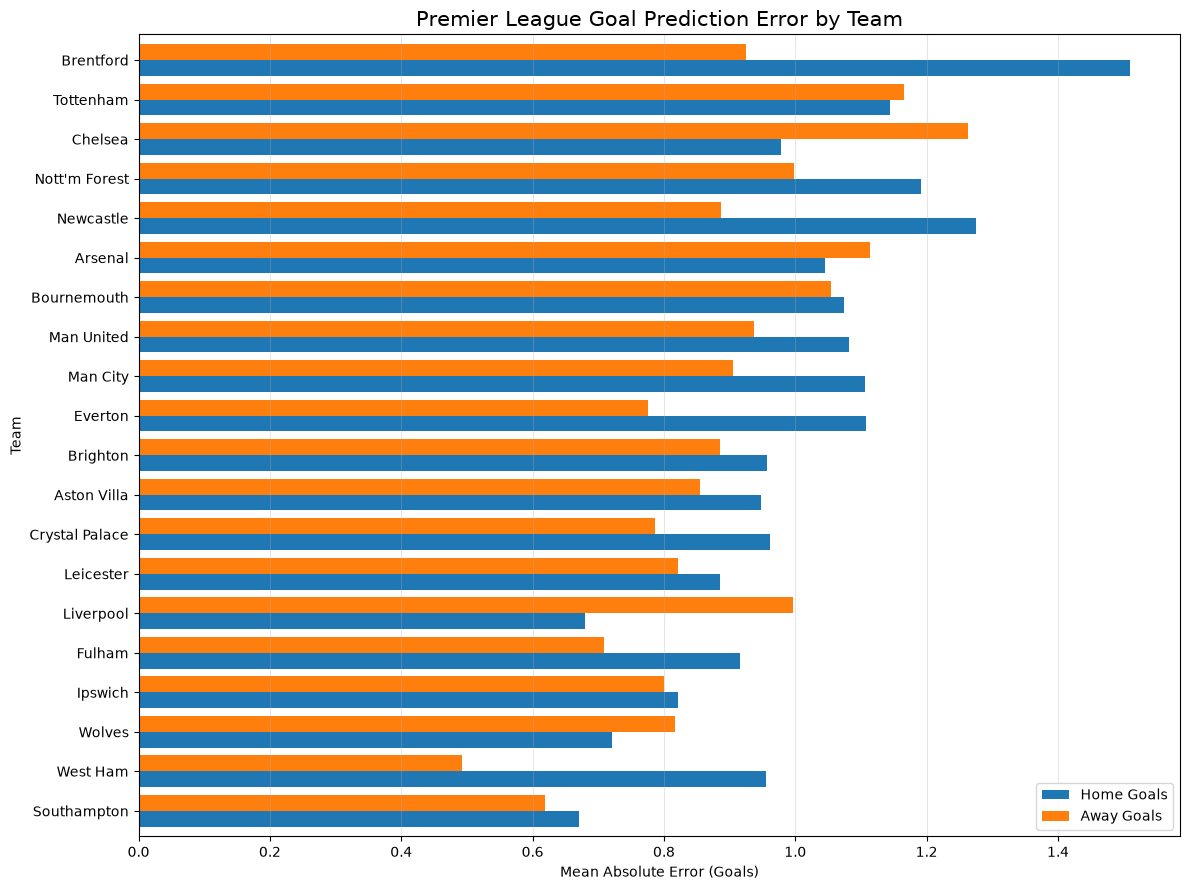

In [42]:
# Sort teams by overall average prediction error
team_comparison['Average_MAE'] = (
    team_comparison['Home_MAE'] +
    team_comparison['Away_MAE']
) / 2

plot_df = team_comparison.sort_values(
    'Average_MAE',
    ascending=True
)

ax = plot_df[
    ['Home_MAE', 'Away_MAE']
].plot(
    kind='barh',
    figsize=(12, 9),
    width=0.8
)

ax.set_title(
    'Premier League Goal Prediction Error by Team',
    fontsize=15
)

ax.set_xlabel('Mean Absolute Error (Goals)')
ax.set_ylabel('Team')

ax.legend(
    ['Home Goals', 'Away Goals'],
    loc='lower right'
)

ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# Prediction time

Lets try and make a prediction with our values, even tho we do not love our MAE

In [43]:
print("Home model features:")
print(home_model.feature_names_in_)

print("\nAway model features:")
print(away_model.feature_names_in_)

print("\nTeam dataframe columns:")
print(team_df.columns.tolist())

print("\nMost recent matches:")
print(
    team_df.sort_values(['Date', 'Time'])
    .groupby('Team')
    .tail(1)[['Team', 'Date', 'Goals_Scored', 'Goals_Conceded']]
    .sort_values('Team')
    .to_string(index=False)
)

Home model features:
['Home_Avg_Goals_Scored_5' 'Home_Avg_Goals_Conceded_5'
 'Away_Avg_Goals_Scored_5' 'Away_Avg_Goals_Conceded_5']

Away model features:
['Home_Avg_Goals_Scored_5' 'Home_Avg_Goals_Conceded_5'
 'Away_Avg_Goals_Scored_5' 'Away_Avg_Goals_Conceded_5']

Team dataframe columns:
['Date', 'Time', 'Season', 'Team', 'Opponent', 'Goals_Scored', 'Goals_Conceded', 'Venue', 'Avg_Goals_Scored_5', 'Avg_Goals_Conceded_5', 'League_Avg_Home_Goals', 'League_Avg_Away_Goals']

Most recent matches:
            Team       Date  Goals_Scored  Goals_Conceded
         Arsenal 2026-05-24             2               1
     Aston Villa 2026-05-24             2               1
     Bournemouth 2026-05-24             1               1
       Brentford 2026-05-24             1               1
        Brighton 2026-05-24             0               3
         Burnley 2026-05-24             1               1
         Chelsea 2026-05-24             1               2
  Crystal Palace 2026-05-24           

In [44]:
def get_latest_team_form(team_name):

    # Get all matches for this team
    team_matches = team_df[
        team_df['Team'] == team_name
    ].sort_values(['Date', 'Time'])

    # Check whether the team exists
    if team_matches.empty:
        raise ValueError(f"Team '{team_name}' not found.")

    # Get the five most recent matches
    recent_matches = team_matches.tail(5)

    # Calculate recent averages
    avg_goals_scored = recent_matches['Goals_Scored'].mean()
    avg_goals_conceded = recent_matches['Goals_Conceded'].mean()

    return {
        'Team': team_name,
        'Avg_Goals_Scored_5': avg_goals_scored,
        'Avg_Goals_Conceded_5': avg_goals_conceded,
        'Last_Match': recent_matches['Date'].max(),
        'Matches_Used': len(recent_matches)
    }

In [45]:
get_latest_team_form('Chelsea')

{'Team': 'Chelsea',
 'Avg_Goals_Scored_5': np.float64(1.0),
 'Avg_Goals_Conceded_5': np.float64(2.0),
 'Last_Match': Timestamp('2026-05-24 00:00:00'),
 'Matches_Used': 5}

In [46]:
get_latest_team_form('Ipswich')

{'Team': 'Ipswich',
 'Avg_Goals_Scored_5': np.float64(0.6),
 'Avg_Goals_Conceded_5': np.float64(2.2),
 'Last_Match': Timestamp('2025-05-25 00:00:00'),
 'Matches_Used': 5}

In [47]:
def prepare_match_features(home_team, away_team):

    home_form = get_latest_team_form(home_team)
    away_form = get_latest_team_form(away_team)

    match_features = pd.DataFrame([{
        'Home_Avg_Goals_Scored_5': home_form['Avg_Goals_Scored_5'],
        'Home_Avg_Goals_Conceded_5': home_form['Avg_Goals_Conceded_5'],
        'Away_Avg_Goals_Scored_5': away_form['Avg_Goals_Scored_5'],
        'Away_Avg_Goals_Conceded_5': away_form['Avg_Goals_Conceded_5']
    }])

    return match_features

In [48]:
chelsea_ipswich = prepare_match_features(
    'Chelsea',
    'Ipswich'
)

chelsea_ipswich

,Home_Avg_Goals_Scored_5,Home_Avg_Goals_Conceded_5,Away_Avg_Goals_Scored_5,Away_Avg_Goals_Conceded_5
0,1.0,2.0,0.6,2.2


In [49]:
home_xg = home_model.predict(chelsea_ipswich)[0]
away_xg = away_model.predict(chelsea_ipswich)[0]

print(f"Chelsea expected goals: {home_xg:.3f}")
print(f"Ipswich expected goals: {away_xg:.3f}")

Chelsea expected goals: 1.544
Ipswich expected goals: 1.133


In [50]:
from scipy.stats import poisson

goal_counts = np.arange(11)

chelsea_goal_probs = poisson.pmf(
    goal_counts, home_xg
)

ipswich_goal_probs = poisson.pmf(
    goal_counts, away_xg
)

goal_probabilities = pd.DataFrame({
    'Goals': goal_counts,
    'Chelsea_Probability': chelsea_goal_probs,
    'Ipswich_Probability': ipswich_goal_probs
})

goal_probabilities

,Goals,Chelsea_Probability,Ipswich_Probability
0,0,0.213439,3.222263e-01
1,1,0.329636,3.649217e-01
2,2,0.254546,2.066371e-01
3,3,0.131040,7.800558e-02
4,4,0.050595,2.208535e-02
5,5,0.015628,5.002338e-03
6,6,0.004023,9.441922e-04
7,7,0.000887,1.527570e-04
8,8,0.000171,2.162468e-05
9,9,0.000029,2.721108e-06


In [51]:
scoreline_matrix = np.outer(
    chelsea_goal_probs,
    ipswich_goal_probs
)

scoreline_df = pd.DataFrame(
    scoreline_matrix,
    index=[f'Chelsea {i}' for i in goal_counts],
    columns=[f'Ipswich {i}' for i in goal_counts]
)

scoreline_df

,Ipswich 0,Ipswich 1,Ipswich 2,Ipswich 3,Ipswich 4,Ipswich 5,Ipswich 6,Ipswich 7,Ipswich 8,Ipswich 9,Ipswich 10
Chelsea 0,0.068776,0.077889,4.410450e-02,1.664947e-02,4.713885e-03,1.067696e-03,2.015278e-04,3.260435e-05,4.615558e-06,5.807917e-07,6.577472e-08
Chelsea 1,0.106217,0.120291,6.811509e-02,2.571347e-02,7.280134e-03,1.648952e-03,3.112400e-04,5.035424e-05,7.128279e-06,8.969760e-07,1.015826e-07
Chelsea 2,0.082021,0.092889,5.259855e-02,1.985597e-02,5.621728e-03,1.273323e-03,2.403399e-04,3.888360e-05,5.504465e-06,6.926459e-07,7.844223e-08
Chelsea 3,0.042225,0.047819,2.707778e-02,1.022187e-02,2.894070e-03,6.555075e-04,1.237272e-04,2.001731e-05,2.833703e-06,3.565747e-07,4.038212e-08
Chelsea 4,0.016303,0.018463,1.045474e-02,3.946670e-03,1.117402e-03,2.530918e-04,4.777113e-05,7.728694e-06,1.094094e-06,1.376737e-07,1.559156e-08
Chelsea 5,0.005036,0.005703,3.229266e-03,1.219049e-03,3.451437e-04,7.817512e-05,1.475557e-05,2.387243e-06,3.379444e-07,4.252471e-08,4.815928e-09
Chelsea 6,0.001296,0.001468,8.312144e-04,3.137838e-04,8.884012e-05,2.012231e-05,3.798089e-06,6.144772e-07,8.698701e-08,1.094588e-08,1.239622e-09
Chelsea 7,0.000286,0.000324,1.833899e-04,6.922977e-05,1.960070e-05,4.439562e-06,8.379682e-07,1.355714e-07,1.919185e-08,2.414977e-09,2.734964e-10
Chelsea 8,0.000055,0.000063,3.540348e-05,1.336483e-05,3.783920e-06,8.570588e-07,1.617700e-07,2.617210e-08,3.704992e-09,4.662120e-10,5.279856e-11
Chelsea 9,0.000009,0.000011,6.075246e-06,2.293408e-06,6.493217e-07,1.470715e-07,2.775978e-08,4.491140e-09,6.357776e-10,8.000209e-11,9.060246e-12


In [52]:
chelsea_win_prob = np.tril(
    scoreline_matrix, k=-1
).sum()

draw_prob = np.trace(scoreline_matrix)

ipswich_win_prob = np.triu(
    scoreline_matrix, k=1
).sum()

print(f"Chelsea win: {chelsea_win_prob:.2%}")
print(f"Draw: {draw_prob:.2%}")
print(f"Ipswich win: {ipswich_win_prob:.2%}")

print(
    f"\nTotal probability: "
    f"{chelsea_win_prob + draw_prob + ipswich_win_prob:.4%}"
)

Chelsea win: 46.81%
Draw: 25.31%
Ipswich win: 27.89%

Total probability: 99.9999%


In [53]:
scoreline_results = []

for home_goals in range(11):
    for away_goals in range(11):

        scoreline_results.append({
            'Chelsea_Goals': home_goals,
            'Ipswich_Goals': away_goals,
            'Probability': scoreline_matrix[
                home_goals, away_goals
            ]
        })

top_scorelines = (
    pd.DataFrame(scoreline_results)
    .sort_values('Probability', ascending=False)
    .head(5)
    .reset_index(drop=True)
)

top_scorelines['Probability'] = (
    top_scorelines['Probability'] * 100
)

top_scorelines

,Chelsea_Goals,Ipswich_Goals,Probability
0,1,1,12.029143
1,1,0,10.621749
2,2,1,9.288918
3,2,0,8.202127
4,0,1,7.788866


In [54]:

def predict_match(home_team, away_team, max_goals=15, top_n=5):

    # 1. Get each team's recent form
    home_form = get_latest_team_form(home_team)
    away_form = get_latest_team_form(away_team)

    # Prevent predicting a team against itself
    if home_team == away_team:
        raise ValueError("Home and away teams must be different.")

    # 2. Prepare model input
    match_features = pd.DataFrame([{
        'Home_Avg_Goals_Scored_5': home_form['Avg_Goals_Scored_5'],
        'Home_Avg_Goals_Conceded_5': home_form['Avg_Goals_Conceded_5'],
        'Away_Avg_Goals_Scored_5': away_form['Avg_Goals_Scored_5'],
        'Away_Avg_Goals_Conceded_5': away_form['Avg_Goals_Conceded_5']
    }])

    # 3. Predict expected goals
    home_xg = home_model.predict(match_features)[0]
    away_xg = away_model.predict(match_features)[0]

    # 4. Calculate individual goal probabilities
    goal_counts = np.arange(max_goals + 1)

    home_goal_probs = poisson.pmf(goal_counts, home_xg)
    away_goal_probs = poisson.pmf(goal_counts, away_xg)

    # 5. Create scoreline probability matrix
    scoreline_matrix = np.outer(
        home_goal_probs,
        away_goal_probs
    )

    # Normalize to account for any tiny probability
    # remaining above max_goals
    scoreline_matrix = (
        scoreline_matrix / scoreline_matrix.sum()
    )

    # 6. Calculate match outcome probabilities
    home_win_prob = np.tril(
        scoreline_matrix, k=-1
    ).sum()

    draw_prob = np.trace(scoreline_matrix)

    away_win_prob = np.triu(
        scoreline_matrix, k=1
    ).sum()

    # 7. Calculate additional probabilities
    btts_prob = scoreline_matrix[1:, 1:].sum()

    over_2_5_prob = sum(
        scoreline_matrix[i, j]
        for i in range(max_goals + 1)
        for j in range(max_goals + 1)
        if i + j > 2.5
    )

    under_2_5_prob = 1 - over_2_5_prob

    # 8. Find the most likely scorelines
    scoreline_results = []

    for home_goals in range(max_goals + 1):
        for away_goals in range(max_goals + 1):

            scoreline_results.append({
                'Home_Goals': home_goals,
                'Away_Goals': away_goals,
                'Probability': scoreline_matrix[
                    home_goals, away_goals
                ]
            })

    top_scorelines = (
        pd.DataFrame(scoreline_results)
        .sort_values('Probability', ascending=False)
        .head(top_n)
        .reset_index(drop=True)
    )

    top_scorelines['Probability'] *= 100

    # 9. Check how current the team data is
    latest_dataset_date = team_df['Date'].max()

    home_data_age = (
        latest_dataset_date - home_form['Last_Match']
    ).days

    away_data_age = (
        latest_dataset_date - away_form['Last_Match']
    ).days

    # 10. Display results
    print(f"\n{home_team} vs. {away_team}")
    print("-" * 40)

    print(f"{home_team} expected goals: {home_xg:.2f}")
    print(f"{away_team} expected goals: {away_xg:.2f}")

    print("\nMatch outcome probabilities:")
    print(f"{home_team} win: {home_win_prob:.2%}")
    print(f"Draw: {draw_prob:.2%}")
    print(f"{away_team} win: {away_win_prob:.2%}")

    print("\nAdditional probabilities:")
    print(f"Both teams to score: {btts_prob:.2%}")
    print(f"Over 2.5 goals: {over_2_5_prob:.2%}")
    print(f"Under 2.5 goals: {under_2_5_prob:.2%}")

    print("\nMost likely scorelines:")
    print(
        top_scorelines.to_string(
            index=False,
            formatters={
                'Probability': lambda x: f"{x:.2f}%"
            }
        )
    )

    print("\nData freshness:")
    print(
        f"{home_team}: {home_form['Last_Match'].date()} "
        f"({home_data_age} days behind dataset end)"
    )
    print(
        f"{away_team}: {away_form['Last_Match'].date()} "
        f"({away_data_age} days behind dataset end)"
    )

    if home_data_age > 90 or away_data_age > 90:
        print("\nWARNING: One or both teams have outdated data.")

    # 11. Return results for further analysis
    return {
        'Home_xG': home_xg,
        'Away_xG': away_xg,
        'Home_Win_Probability': home_win_prob,
        'Draw_Probability': draw_prob,
        'Away_Win_Probability': away_win_prob,
        'BTTS_Probability': btts_prob,
        'Over_2.5_Probability': over_2_5_prob,
        'Under_2.5_Probability': under_2_5_prob,
        'Top_Scorelines': top_scorelines,
        'Scoreline_Matrix': scoreline_matrix,
        'Home_Last_Match': home_form['Last_Match'],
        'Away_Last_Match': away_form['Last_Match']
    }


In [55]:
chelsea_vs_ipswich = predict_match(
    'Chelsea',
    'Ipswich'
)


Chelsea vs. Ipswich
----------------------------------------
Chelsea expected goals: 1.54
Ipswich expected goals: 1.13

Match outcome probabilities:
Chelsea win: 46.81%
Draw: 25.31%
Ipswich win: 27.89%

Additional probabilities:
Both teams to score: 53.31%
Over 2.5 goals: 50.07%
Under 2.5 goals: 49.93%

Most likely scorelines:
 Home_Goals  Away_Goals Probability
          1           1      12.03%
          1           0      10.62%
          2           1       9.29%
          2           0       8.20%
          0           1       7.79%

Data freshness:
Chelsea: 2026-05-24 (0 days behind dataset end)
Ipswich: 2025-05-25 (364 days behind dataset end)



In [56]:
chelsea_vs_ipswich['Home_Win_Probability']

np.float64(0.4680606498915139)

In [57]:
chelsea_vs_ipswich['Top_Scorelines']

,Home_Goals,Away_Goals,Probability
0,1,1,12.029143
1,1,0,10.621749
2,2,1,9.288918
3,2,0,8.202127
4,0,1,7.788866


In [58]:
man_city_vs_norwich = predict_match(
    'Man City',
    'Norwich'
)


Man City vs. Norwich
----------------------------------------
Man City expected goals: 2.52
Norwich expected goals: 0.78

Match outcome probabilities:
Man City win: 75.15%
Draw: 15.41%
Norwich win: 9.44%

Additional probabilities:
Both teams to score: 49.77%
Over 2.5 goals: 63.98%
Under 2.5 goals: 36.02%

Most likely scorelines:
 Home_Goals  Away_Goals Probability
          2           0      11.72%
          3           0       9.83%
          1           0       9.32%
          2           1       9.14%
          3           1       7.67%

Data freshness:
Man City: 2026-05-24 (0 days behind dataset end)
Norwich: 2022-05-22 (1463 days behind dataset end)



In [59]:
man_city_vs_norwich['Home_Win_Probability']

np.float64(0.7514644870380375)

In [60]:
man_city_vs_norwich['Top_Scorelines']

,Home_Goals,Away_Goals,Probability
0,2,0,11.722660
1,3,0,9.833781
2,1,0,9.316238
3,2,1,9.140336
4,3,1,7.667548
